# Entregable II — Etapa 1: perfiles de pago (clustering)

Modelos y Simulación de Sistemas II — Universidad de Antioquia — Grupo 14

Este notebook construye la **etapa no supervisada** del sistema: agrupar los episodios
según su comportamiento de pago en las primeras *K* = 8 semanas. El perfil resultante
alimenta la etapa supervisada (`03_clasificacion`).

**Dos cuidados metodológicos** (retroalimentación del Entregable I):

1. **Sin fuga entre etapas.** El escalado, la imputación y el clustering se ajustan solo
   con los episodios de entrenamiento. A los de prueba únicamente se les *asigna* un
   perfil con el modelo ya entrenado (`predict`/`transform`, nunca `fit`).
2. **Validación temporal.** Los episodios se ordenan por `fecha_inicio`: los más antiguos
   entrenan y el 20 % más reciente prueba. Se purgan del entrenamiento los episodios cuya
   etiqueta se resuelve después de que empieza la prueba (`src/particion.py`).

La etiqueta `y` **no se usa para formar los perfiles ni para elegir *K***; solo se usa
después, para describir el riesgo de cada perfil. La explicación de cada variable y su
tratamiento están en `01_eda.ipynb` y en `reports/diccionario_datos.csv`.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

EN_COLAB = "google.colab" in sys.modules
NOMBRE_CARPETA = "ProyectoModelos2_Colab"


def buscar_carpeta_drive():
    raices = [Path("/content/drive/MyDrive"), *Path("/content/drive").glob(".shortcut-targets-by-id/*")]
    for patron in (NOMBRE_CARPETA, f"*/{NOMBRE_CARPETA}", f"*/*/{NOMBRE_CARPETA}"):
        for raiz in raices:
            for carpeta in raiz.glob(patron):
                if (carpeta / "modelado.py").exists():
                    return carpeta
    return None


if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    carpeta = buscar_carpeta_drive()
    if carpeta is None:
        raise FileNotFoundError(
            f"No se encontro la carpeta {NOMBRE_CARPETA} en su Drive. Agreguele un acceso directo "
            "en Mi unidad (Compartidos conmigo > clic derecho > Organizar > Agregar acceso directo) "
            "y vuelva a ejecutar todo.")
    os.chdir(carpeta)
RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DIR_SALIDA = Path("/content/salidas") if EN_COLAB else RAIZ


def ubicar(archivos, carpetas):
    for c in carpetas:
        if all((c / a).exists() for a in archivos):
            return c
    raise FileNotFoundError(f"No se encontraron {archivos} en {[str(c) for c in carpetas]}.")


sys.path.insert(0, str(ubicar(["modelado.py", "particion.py"], [RAIZ / "src", Path.cwd()])))
DIR_DATOS = ubicar(["dataset_modelo.csv.gz"], [RAIZ / "data" / "anon", Path.cwd()])
DIR_FIG = DIR_SALIDA / "reports" / "figuras"
DIR_FIG.mkdir(parents=True, exist_ok=True)

from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture

from modelado import COLS_PERFIL, Perfil
from particion import corte_por_fraccion, dividir_temporal, pliegues_expansivos

TINTA, TINTA_2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e0"
AZUL, NARANJA = "#2a78d6", "#eb6834"
# Perfiles ordenados de menor a mayor riesgo: rampa de un solo matiz
COLORES = ["#f2c14e", "#f78154", "#d1495b", "#6b2737", "#3d1a24", "#1c0d12"]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": REJILLA,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
})
CIFRAS = {}
SEMILLA = 0

## 1. Datos y partición temporal

Parámetros del estudio (los mismos del EDA): ventana de observación `K` = 8 semanas,
horizonte `H` = 12 semanas, atraso grave `X` = 14 días. La purga de la partición depende
de estos tres valores.

In [2]:
K, H, X = 8, 12, 14
d = pd.read_csv(DIR_DATOS / "dataset_modelo.csv.gz", parse_dates=["fecha_inicio"])
corte = corte_por_fraccion(d.fecha_inicio, 0.2)
i_tr, i_te = dividir_temporal(d.fecha_inicio, K, H, X, corte)
A, B = d.iloc[i_tr].reset_index(drop=True), d.iloc[i_te].reset_index(drop=True)
purgados = int((d.fecha_inicio < corte).sum() - len(A))

resumen = pd.DataFrame({
    "episodios": [len(A), len(B)],
    "inicio desde": [A.fecha_inicio.min().date(), B.fecha_inicio.min().date()],
    "inicio hasta": [A.fecha_inicio.max().date(), B.fecha_inicio.max().date()],
    "% riesgo grave": [round(100 * A.y.mean(), 1), round(100 * B.y.mean(), 1)],
}, index=["entrenamiento", "prueba"])
display(resumen)
print(f"Fecha de corte: {corte.date()}. Purgados del entrenamiento: {purgados} episodios "
      "(su etiqueta se resuelve despues del corte).")
CIFRAS["particion"] = {"corte": str(corte.date()), "train": len(A), "test": len(B), "purgados": purgados,
                       "riesgo_train": round(float(A.y.mean()), 4), "riesgo_test": round(float(B.y.mean()), 4)}

,episodios,inicio desde,inicio hasta,% riesgo grave
entrenamiento,1735,2024-03-31,2025-07-02,32.0
prueba,582,2025-12-03,2026-07-29,38.7


Fecha de corte: 2025-12-03. Purgados del entrenamiento: 572 episodios (su etiqueta se resuelve despues del corte).


El riesgo grave es mayor en los episodios recientes que en los antiguos: la cartera se
deterioró con el tiempo. Una partición aleatoria habría ocultado ese cambio, y por eso
las métricas de este notebook y del siguiente serán más exigentes (y más honestas) que
las de una validación cruzada sin orden temporal.

## 2. Elección del número de perfiles *K*

Se comparan de 2 a 7 perfiles con tres criterios, **todos calculados sin la etiqueta**:

- **Codo** (inercia en entrenamiento).
- **Silueta**, medida en entrenamiento y en validación temporal (pliegues de ventana
  expansiva; en cada pliegue el modelo se ajusta solo con lo anterior y se evalúa en el
  tramo siguiente).
- **Estabilidad**: se ajusta el clustering con la primera y con la segunda mitad (en el
  tiempo) del entrenamiento y se mide el acuerdo entre ambas asignaciones sobre los mismos
  episodios con el índice de Rand ajustado (ARI). Un valor cercano a 1 indica que los
  perfiles no dependen del periodo usado.

,inercia,silueta train,silueta validación,estabilidad (ARI)
K,,,,
2,10822.202,0.537,0.438,0.987
3,7248.666,0.370,0.359,0.894
4,6167.789,0.329,0.326,0.812
5,5267.390,0.339,0.300,0.569
6,4700.911,0.323,0.303,0.679
7,4210.350,0.330,0.303,0.755


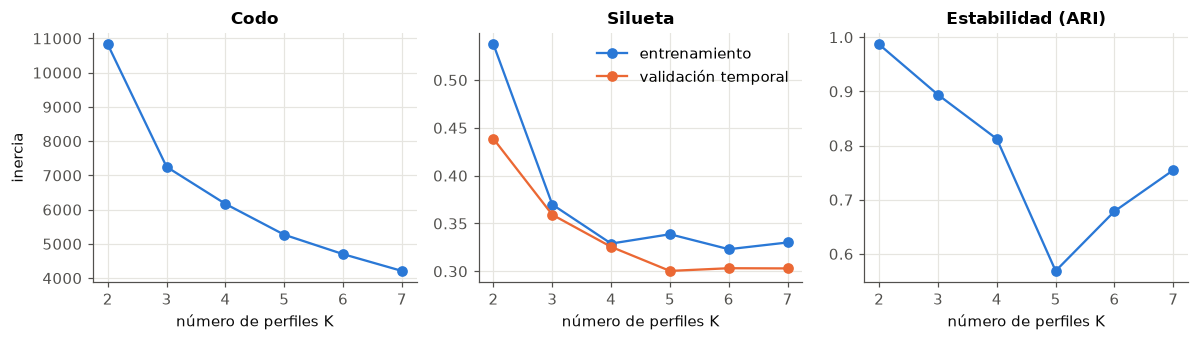

In [3]:
pliegues = pliegues_expansivos(d.fecha_inicio, K, H, X, n_splits=4, fecha_max=corte)
mitad = len(A) // 2
filas = []
for k in range(2, 8):
    p = Perfil(k, seed=SEMILLA).fit(A)
    Z_tr = p.prep_.transform(A[p.cols_])
    sil_tr = silhouette_score(Z_tr, p.predict(A))
    sil_val = []
    for tr, va in pliegues:
        if len(tr) < 50:
            continue
        pf = Perfil(k, seed=SEMILLA).fit(d.iloc[tr])
        sil_val.append(silhouette_score(pf.prep_.transform(d.iloc[va][pf.cols_]), pf.predict(d.iloc[va])))
    a1 = Perfil(k, seed=SEMILLA).fit(A.iloc[:mitad]).predict(B)
    a2 = Perfil(k, seed=SEMILLA).fit(A.iloc[mitad:]).predict(B)
    filas.append({"K": k, "inercia": p.km_.inertia_, "silueta train": sil_tr,
                  "silueta validación": np.mean(sil_val), "estabilidad (ARI)": adjusted_rand_score(a1, a2)})
sel = pd.DataFrame(filas).set_index("K")
display(sel.round(3))

fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
ax[0].plot(sel.index, sel.inercia, marker="o", color=AZUL); ax[0].set_title("Codo"); ax[0].set_ylabel("inercia")
ax[1].plot(sel.index, sel["silueta train"], marker="o", color=AZUL, label="entrenamiento")
ax[1].plot(sel.index, sel["silueta validación"], marker="o", color=NARANJA, label="validación temporal")
ax[1].set_title("Silueta"); ax[1].legend(frameon=False)
ax[2].plot(sel.index, sel["estabilidad (ARI)"], marker="o", color=AZUL); ax[2].set_title("Estabilidad (ARI)")
for a in ax: a.set_xlabel("número de perfiles K")
fig.tight_layout(); fig.savefig(DIR_FIG / "seleccion_k.png"); plt.show()
CIFRAS["seleccion_k"] = sel.round(4).to_dict(orient="index")

**Lectura.** La silueta y la estabilidad son máximas con 2 perfiles, que solo separan a
quienes pagan bien de quienes no. Con 3 y 4 perfiles la estabilidad sigue siendo buena
(ARI cercano o superior a 0,8 con 4), pero cae con 5 o más: son perfiles que cambian según
el periodo con que se ajusten. Se elige ***K* = 4** como el mayor número de perfiles que se
mantiene estable, porque permite diferenciar niveles de riesgo útiles para el cobro (ver
sección 4). Esta decisión se tomó con criterios no supervisados, antes de mirar el riesgo
por perfil.

In [4]:
KP = 4
modelo = Perfil(KP, seed=SEMILLA).fit(A)
A["perfil"] = modelo.predict(A)
B["perfil"] = modelo.predict(B)          # solo predict: la prueba no participa en el ajuste
Z_tr = modelo.prep_.transform(A[modelo.cols_])
Z_te = modelo.prep_.transform(B[modelo.cols_])

## 3. Comparación de algoritmos

Se comparan tres algoritmos vistos en el curso con el mismo *K* = 4 y el mismo
preprocesamiento: **k-means**, **jerárquico aglomerativo (Ward)** y **mezcla de
gaussianas (GMM)**. El jerárquico no tiene un `predict`; para asignar perfiles a la
prueba se usa el centroide más cercano de los grupos formados en entrenamiento. En todos
los casos los perfiles se numeran de menor a mayor atraso promedio.

In [5]:
def ordenar_por_atraso(etiquetas, Z, cols):
    j = cols.index("atraso_promedio")
    medias = {c: Z[etiquetas == c, j].mean() for c in np.unique(etiquetas)}
    mapa = {c: i for i, c in enumerate(sorted(medias, key=medias.get))}
    return np.array([mapa[c] for c in etiquetas]), mapa

cols = modelo.cols_
# k-means
et_km_tr, et_km_te = A.perfil.to_numpy(), B.perfil.to_numpy()
# jerarquico (Ward)
h = AgglomerativeClustering(n_clusters=KP, linkage="ward").fit(Z_tr)
et_h_tr, mapa_h = ordenar_por_atraso(h.labels_, Z_tr, cols)
cent_h = np.vstack([Z_tr[et_h_tr == c].mean(axis=0) for c in range(KP)])
et_h_te = ((Z_te[:, None, :] - cent_h[None]) ** 2).sum(axis=2).argmin(axis=1)
# GMM
g = GaussianMixture(KP, covariance_type="full", n_init=5, random_state=SEMILLA).fit(Z_tr)
et_g_tr, mapa_g = ordenar_por_atraso(g.predict(Z_tr), Z_tr, cols)
et_g_te = np.array([mapa_g[c] for c in g.predict(Z_te)])

algs = {"k-means": (et_km_tr, et_km_te), "jerárquico (Ward)": (et_h_tr, et_h_te), "GMM": (et_g_tr, et_g_te)}
filas = []
for nombre, (e_tr, e_te) in algs.items():
    r_tr = pd.Series(A.y.to_numpy()).groupby(e_tr).mean()
    r_te = pd.Series(B.y.to_numpy()).groupby(e_te).mean()
    filas.append({
        "algoritmo": nombre,
        "silueta train": silhouette_score(Z_tr, e_tr),
        "silueta prueba": silhouette_score(Z_te, e_te),
        "ARI vs k-means (train)": adjusted_rand_score(et_km_tr, e_tr),
        "riesgo por perfil, train (%)": " / ".join(f"{100*v:.0f}" for v in r_tr),
        "riesgo por perfil, prueba (%)": " / ".join(f"{100*r_te.get(i, np.nan):.0f}" for i in range(KP)),
        "tamaños, prueba": " / ".join(str(int((e_te == i).sum())) for i in range(KP)),
    })
comp = pd.DataFrame(filas).set_index("algoritmo")
display(comp.round(3))
CIFRAS["comparacion_algoritmos"] = comp.round(4).to_dict(orient="index")

,silueta train,silueta prueba,ARI vs k-means (train),"riesgo por perfil, train (%)","riesgo por perfil, prueba (%)","tamaños, prueba"
algoritmo,,,,,,
k-means,0.329,0.292,1.000,15 / 29 / 59 / 81,19 / 37 / 74 / 73,232 / 210 / 125 / 15
jerárquico (Ward),0.281,0.268,0.696,14 / 27 / 55 / 77,18 / 34 / 71 / 77,236 / 177 / 156 / 13
GMM,0.304,0.254,0.646,13 / 32 / 56 / 77,16 / 44 / 64 / nan,200 / 250 / 132 / 0


Se usa **k-means** para la etapa supervisada: es el más simple, el único de los tres con
`predict` nativo y sus centroides son interpretables. Los tres ordenan el riesgo de menor a
mayor en entrenamiento; el jerárquico y el GMM coinciden solo en parte con k-means (ARI
entre 0,6 y 0,7) y tienen una silueta menor. Además, el GMM no asigna a ningún episodio de
prueba al perfil más grave, y en k-means ese perfil tiene apenas 15: su porcentaje de riesgo
en prueba es poco preciso.

## 4. Caracterización de los perfiles

,episodios (train),episodios (prueba),% riesgo grave (train),% riesgo grave (prueba)
0 · Puntual,654,232,14.7,18.5
1 · Atrasos leves,670,210,29.0,37.1
2 · Se va quedando,300,125,58.7,74.4
3 · No paga,111,15,81.1,73.3


,0 · Puntual,1 · Atrasos leves,2 · Se va quedando,3 · No paga
prop_ciclos_atrasados,0.03,0.31,0.71,0.94
prop_ciclos_atraso_3mas,0.01,0.03,0.39,0.86
atraso_promedio,0.07,0.47,3.08,23.73
ciclos_sin_pagar_k,0.06,0.19,1.29,7.32
pagos_por_ciclo,1.00,0.99,0.84,0.08
deficit_relativo,0.04,0.07,0.20,0.92
multa_acumulada,0.05,45.70,85.12,2.12
prop_pagos_con_multa,0.00,0.29,0.54,0.25
cv_pago_canon,0.14,0.16,0.18,0.17
dias_hasta_primer_pago,4.77,4.74,5.49,7.81


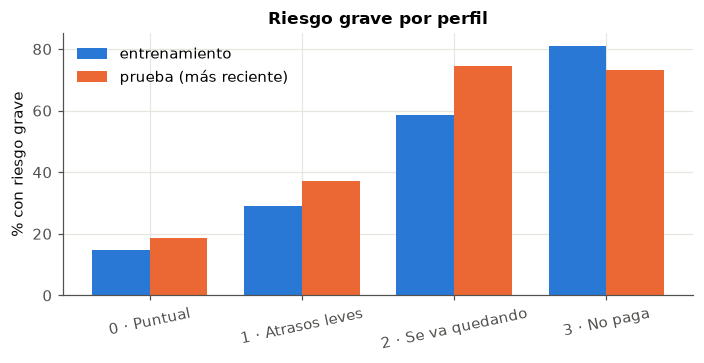

In [6]:
perfil_nombre = {0: "Puntual", 1: "Atrasos leves", 2: "Se va quedando", 3: "No paga"}
tabla = pd.DataFrame({
    "episodios (train)": A.perfil.value_counts().sort_index(),
    "episodios (prueba)": B.perfil.value_counts().sort_index(),
    "% riesgo grave (train)": (100 * A.groupby("perfil").y.mean()).round(1),
    "% riesgo grave (prueba)": (100 * B.groupby("perfil").y.mean()).round(1),
}).fillna(0)
tabla.index = [f"{i} · {perfil_nombre[i]}" for i in tabla.index]
display(tabla)

medias = A.groupby("perfil")[COLS_PERFIL].mean().round(2)
medias.index = [f"{i} · {perfil_nombre[i]}" for i in medias.index]
display(medias.T)
CIFRAS["perfiles"] = {"tabla": tabla.to_dict(orient="index"), "medias": medias.to_dict(orient="index")}

fig, ax = plt.subplots(figsize=(6.5, 3.4))
x = np.arange(KP); w = 0.38
ax.bar(x - w/2, tabla["% riesgo grave (train)"], w, color=AZUL, label="entrenamiento")
ax.bar(x + w/2, tabla["% riesgo grave (prueba)"], w, color=NARANJA, label="prueba (más reciente)")
ax.set_xticks(x); ax.set_xticklabels(tabla.index, rotation=12); ax.set_ylabel("% con riesgo grave")
ax.set_title("Riesgo grave por perfil"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(DIR_FIG / "riesgo_por_perfil.png"); plt.show()

Los nombres de los perfiles son una descripción de las medias de la tabla, no una
variable del modelo. Al comparar entrenamiento y prueba hay que tener presente que los
episodios recientes son más riesgosos y que un perfil con pocos episodios en prueba da un
porcentaje poco preciso.

## 5. Visualización: PCA y UMAP

Ambas proyecciones se ajustan **solo con entrenamiento**; la prueba se proyecta con el
modelo ya ajustado.

C:\Users\LeNoVo\Documents\proyecto_modelos_2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\LeNoVo\Documents\proyecto_modelos_2\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


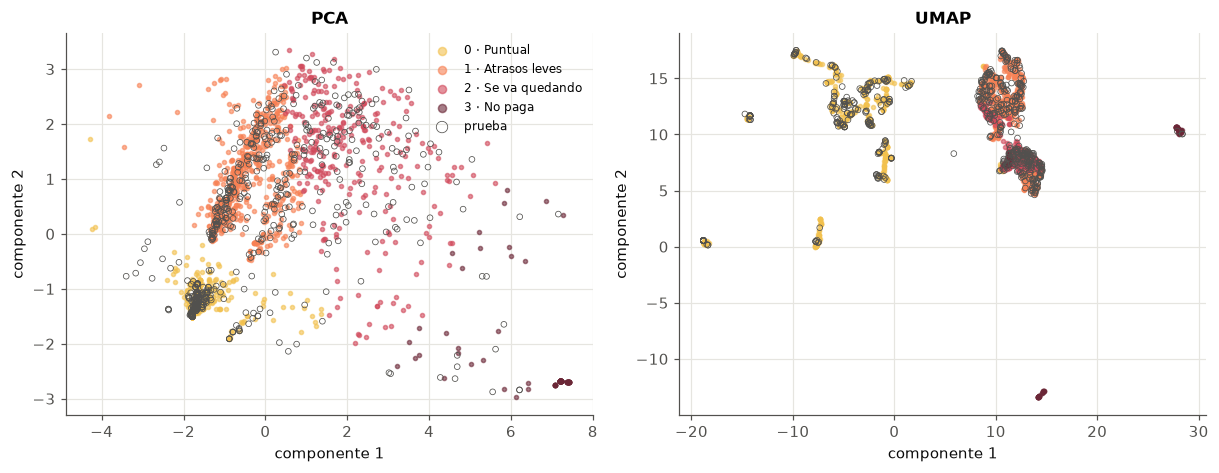

Varianza explicada por las 2 primeras componentes (PCA): [0.519 0.217]


In [7]:
pca = PCA(n_components=2, random_state=SEMILLA).fit(Z_tr)
P_tr, P_te = pca.transform(Z_tr), pca.transform(Z_te)
try:
    import umap
    um = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.2, random_state=SEMILLA).fit(Z_tr)
    U_tr, U_te = um.embedding_, um.transform(Z_te)
    proy = {"PCA": (P_tr, P_te), "UMAP": (U_tr, U_te)}
except ImportError:
    print("umap-learn no esta instalado: solo se muestra PCA (pip install umap-learn).")
    proy = {"PCA": (P_tr, P_te)}

fig, ax = plt.subplots(1, len(proy), figsize=(5.6 * len(proy), 4.4), squeeze=False)
for a, (nombre, (p_tr, p_te)) in zip(ax[0], proy.items()):
    for c in range(KP):
        m = A.perfil.to_numpy() == c
        a.scatter(p_tr[m, 0], p_tr[m, 1], s=7, color=COLORES[c], alpha=0.6, label=f"{c} · {perfil_nombre[c]}")
    a.scatter(p_te[:, 0], p_te[:, 1], s=14, facecolors="none", edgecolors=TINTA_2, linewidths=0.5, label="prueba")
    a.set_title(nombre); a.set_xlabel("componente 1"); a.set_ylabel("componente 2")
ax[0][0].legend(frameon=False, fontsize=8, markerscale=2)
fig.tight_layout(); fig.savefig(DIR_FIG / "proyeccion_perfiles.png"); plt.show()
print("Varianza explicada por las 2 primeras componentes (PCA):", pca.explained_variance_ratio_.round(3))
CIFRAS["pca_var_explicada"] = pca.explained_variance_ratio_.round(4).tolist()

## 6. Resumen y salida para la etapa supervisada

- Se eligió *K* = 4 perfiles con k-means, por estabilidad y utilidad, sin usar la etiqueta.
- El modelo de perfiles (`Perfil`, en `src/modelado.py`) se ajustará **dentro de cada
  pliegue** del notebook 03, sin ver nunca los datos de validación ni de prueba.

In [8]:
(DIR_SALIDA / "reports" / "cifras_clustering.json").write_text(
    json.dumps(CIFRAS, indent=2, ensure_ascii=False, default=lambda o: float(o) if hasattr(o, "item") else str(o)),
    encoding="utf-8")
print("Resultados guardados en", DIR_SALIDA / "reports")

Resultados guardados en C:\Users\LeNoVo\Documents\proyecto_modelos_2\reports
